# Predictive Maintenance — Interim Analysis

Harshit Rathi

Source: Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.

The healthy/faulty mapping remains unverified because external sources conflict. This report retains class 0/class 1 terminology throughout. Class 1 is the positive class solely for statistical evaluation; it does not imply healthy, faulty, or better condition.

Reproduction: run from the project root with data/engine_data.csv present; install requirements.txt. The analytical source is embedded below. All EDA uses training rows; the test set is reserved for final evaluation.

### Source verification and conflicting label definitions

- [Original dataset: Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023)](https://www.kaggle.com/datasets/parvmodi/automotive-vehicles-engine-health-dataset): The downloaded CSV exactly matches the supplied file. The retrieved source metadata does not define the target-class meanings.

- [Hossein Nafar, master thesis, University of Wuppertal (2024), printed page 30 / PDF page 41](https://www.vzu.uni-wuppertal.de/fileadmin/site/vzu/Masterarbeit_HosseinNafar.pdf#page=41): Describes class 1 as healthy and class 0 as out of operation or failed; reference 47 cites the matching Kaggle dataset.

- [Jayden P. Chen, Fusion of Neural Networks and Logistic Regression for Predictive Maintenance of Vehicle Engines (2024), Table 1, page 66](https://ajosr.org/wp-content/uploads/journal/published_paper/volume-2/issue-2/ajsr2024_pFcUxi32.pdf#page=3): Describes class 1 as indicating a need for maintenance. Its sensor summary statistics match this dataset, although its stated row count differs.

The disagreement is unresolved. Sensor averages cannot establish label semantics without verified ground truth. No labels have been reversed or renamed.

In [1]:
"""Reproducible binary-classification workflow; configure against the assigned dataset."""
import argparse
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
    confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd()

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, default=str))

def load_config(path):
    cfg = json.loads(Path(path).read_text())
    for key in ['dataset', 'source', 'target', 'positive_label', 'expected_columns', 'drop_columns']:
        if key not in cfg:
            raise ValueError(f'Missing configuration field: {key}')
    if not cfg['expected_columns'] or not cfg['source']:
        raise ValueError('Provide the documented expected columns and dataset source.')
    return cfg

def validate(cfg):
    path = (ROOT / cfg['dataset']).resolve()
    if not path.is_relative_to((ROOT / 'data').resolve()):
        raise ValueError('The dataset must be loaded from the repository data folder.')
    df = pd.read_csv(path)
    if df.empty or not df.columns.is_unique:
        raise ValueError('Dataset must be nonempty with unique column names.')
    missing = set(cfg['expected_columns']) - set(df.columns)
    extra = set(df.columns) - set(cfg['expected_columns'])
    if missing or extra:
        raise ValueError(f'Schema mismatch: missing={sorted(missing)}, unexpected={sorted(extra)}')
    target = cfg['target']
    if target not in df or df[target].isna().any() or df[target].nunique() != 2:
        raise ValueError('Target must contain exactly two classes and no missing labels.')
    if cfg['positive_label'] not in df[target].unique():
        raise ValueError('positive_label is absent from the target.')
    if target in cfg['drop_columns'] or set(cfg['drop_columns']) - set(df):
        raise ValueError('Invalid drop_columns configuration.')
    for col in cfg.get('numeric_columns', []):
        df[col] = pd.to_numeric(df[col], errors='raise')
        if np.isinf(df[col].dropna()).any():
            raise ValueError(f'Infinite values in {col}')
    summary = {'rows': len(df), 'columns': list(df), 'missing': df.isna().sum().to_dict(),
               'duplicate_rows': int(df.duplicated().sum()),
               'class_counts': df[target].value_counts().to_dict(),
               'source': cfg['source'], 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    return df, summary

def prepare(cfg, out):
    df, summary = validate(cfg)
    save_json(out / 'registration.json', summary)
    print(json.dumps(summary, indent=2, default=str))
    # Remove IDs and post-outcome leakage fields before deduplication and splitting.
    df = df.drop(columns=cfg['drop_columns']).drop_duplicates()
    target = cfg['target']
    if len(df.columns) < 2:
        raise ValueError('No predictors remain.')
    if df.drop(columns=target).isna().all().any():
        raise ValueError('Remove entirely empty predictors in the configuration.')
    if df.groupby(list(df.drop(columns=target)), dropna=False)[target].nunique().gt(1).any():
        raise ValueError('Identical predictors have conflicting labels; resolve before splitting.')
    df[target] = (df[target] == cfg['positive_label']).astype(int)
    train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target])
    if train[target].value_counts().min() < 3:
        raise ValueError('Training data needs at least three observations in each class.')
    out.mkdir(parents=True, exist_ok=True)
    train.to_csv(out / 'train.csv', index=False)
    test.to_csv(out / 'test.csv', index=False)
    save_json(out / 'split_metadata.json', {'train_rows': len(train), 'test_rows': len(test),
        'removed_rows': summary['rows'] - len(df), 'seed': 42, 'target': target,
        'positive_label': cfg['positive_label'], 'drop_columns': cfg['drop_columns'],
        'source_sha256': summary['sha256'],
        'split_sha256': {name: hashlib.sha256((out / f'{name}.csv').read_bytes()).hexdigest()
                         for name in ['train', 'test']}})
    return train, test

def evaluate(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {'average_precision': average_precision_score(y, prob), 'roc_auc': roc_auc_score(y, prob),
            'balanced_accuracy': balanced_accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0), 'f1': f1_score(y, pred, zero_division=0),
            'confusion_matrix': confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def train_model(cfg, splits, out):
    metadata = json.loads((splits / 'split_metadata.json').read_text())
    for key in ['target', 'positive_label', 'drop_columns']:
        if metadata[key] != cfg[key]:
            raise ValueError(f'Split artifact configuration mismatch: {key}')
    for name, digest in metadata['split_sha256'].items():
        if hashlib.sha256((splits / f'{name}.csv').read_bytes()).hexdigest() != digest:
            raise ValueError(f'Split artifact checksum mismatch: {name}')
    train, test = (pd.read_csv(splits / f'{name}.csv') for name in ['train', 'test'])
    target = cfg['target']
    X, y = train.drop(columns=target), train[target]
    Xt, yt = test.drop(columns=target), test[target]
    numeric = X.select_dtypes(include='number').columns.tolist()
    categorical = [c for c in X if c not in numeric]
    preprocessing = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore'))]), categorical)])
    model = Pipeline([('preprocessing', preprocessing),
                      ('model', RandomForestClassifier(random_state=42, n_jobs=1))])
    grid = {'model__n_estimators': [100, 200], 'model__max_depth': [None, 10],
            'model__min_samples_leaf': [1, 3], 'model__class_weight': [None, 'balanced']}
    search = GridSearchCV(model, grid, scoring='average_precision',
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42), n_jobs=4,
        return_train_score=True, error_score='raise')
    search.fit(X, y)
    baseline = DummyClassifier(strategy='prior').fit(X, y)
    metrics = {'baseline': evaluate(baseline, Xt, yt), 'random_forest': evaluate(search.best_estimator_, Xt, yt),
               'best_cv_average_precision': search.best_score_, 'best_parameters': search.best_params_,
               'test_prevalence': float(yt.mean()), 'decision_threshold': 0.5}
    out.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(search.cv_results_).to_csv(out / 'experiments.csv', index=False)
    save_json(out / 'metrics.json', metrics)
    save_json(out / 'best_parameters.json', search.best_estimator_.get_params(deep=True))
    save_json(out / 'run_metadata.json', {'configuration': cfg, 'splits': metadata,
        'python': platform.python_version(),
        'packages': {name: version(name) for name in ['pandas', 'numpy', 'scikit-learn', 'joblib']},
        'selection_metric': 'average_precision', 'folds': 3, 'seed': 42,
        'candidate_count': len(search.cv_results_['params'])})
    joblib.dump(search.best_estimator_, out / 'best_model.joblib')
    print(json.dumps(metrics, indent=2))
    return metrics

print("Validation and modeling functions loaded; random seed = 42.")

Validation and modeling functions loaded; random seed = 42.


## 1. Data registration and preparation

Methodology: validate all seven columns, numeric features, binary labels, missing values and duplicates; hash the input. Retain all six sensors, remove exact duplicates if present and stratify an 80/20 split. Learn imputation inside cross-validation. No timestamp or equipment identifier is available for a time/group split.

In [2]:
cfg = {'dataset': 'data/engine_data.csv', 'source': 'Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.', 'learner_name': 'Harshit Rathi', 'target': 'Engine Condition', 'positive_label': 1, 'expected_columns': ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp', 'Engine Condition'], 'numeric_columns': ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp'], 'drop_columns': [], 'label_note': 'The healthy/faulty mapping remains unverified because external sources conflict. This report retains class 0/class 1 terminology throughout. Class 1 is the positive class solely for statistical evaluation; it does not imply healthy, faulty, or better condition.', 'source_url': 'https://www.kaggle.com/datasets/parvmodi/automotive-vehicles-engine-health-dataset', 'label_evidence': [{'title': 'Original dataset: Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023)', 'url': 'https://www.kaggle.com/datasets/parvmodi/automotive-vehicles-engine-health-dataset', 'finding': 'The downloaded CSV exactly matches the supplied file. The retrieved source metadata does not define the target-class meanings.'}, {'title': 'Hossein Nafar, master thesis, University of Wuppertal (2024), printed page 30 / PDF page 41', 'url': 'https://www.vzu.uni-wuppertal.de/fileadmin/site/vzu/Masterarbeit_HosseinNafar.pdf#page=41', 'finding': 'Describes class 1 as healthy and class 0 as out of operation or failed; reference 47 cites the matching Kaggle dataset.'}, {'title': 'Jayden P. Chen, Fusion of Neural Networks and Logistic Regression for Predictive Maintenance of Vehicle Engines (2024), Table 1, page 66', 'url': 'https://ajosr.org/wp-content/uploads/journal/published_paper/volume-2/issue-2/ajsr2024_pFcUxi32.pdf#page=3', 'finding': 'Describes class 1 as indicating a need for maintenance. Its sensor summary statistics match this dataset, although its stated row count differs.'}]}
splits = Path('artifacts/splits')
train, test = prepare(cfg, splits)
print('Label interpretation:', cfg['label_note'])
print('Training shape:', train.shape, 'Test shape:', test.shape)
print('No features dropped; no missing values or exact duplicates in the supplied file.')


{
  "rows": 19535,
  "columns": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp",
    "Engine Condition"
  ],
  "missing": {
    "Engine rpm": 0,
    "Lub oil pressure": 0,
    "Fuel pressure": 0,
    "Coolant pressure": 0,
    "lub oil temp": 0,
    "Coolant temp": 0,
    "Engine Condition": 0
  },
  "duplicate_rows": 0,
  "class_counts": {
    "1": 12317,
    "0": 7218
  },
  "source": "Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.",
  "sha256": "616c7b985ec00e299061f02b11fd866f8eca16b5e8d15d4a61a5fbfd116b8045"
}
Label interpretation: The healthy/faulty mapping remains unverified because external sources conflict. This report retains class 0/class 1 terminology throughout. Class 1 is the positive 

## 2. Exploratory analysis

Methodology: summarize training distributions, compare feature means and boxplots by class, calculate Pearson correlations, and flag 1.5-IQR extremes without deleting them. Sensor units, collection process and target meanings were not provided.

Table 1. Training feature overview; pressure/temperature units were not supplied.


,count,mean,std,min,25%,50%,75%,max,IQR flags
Engine rpm,15628.0,792.26,267.34,61.00,594.00,748.00,934.00,2239.00,371
Lub oil pressure,15628.0,3.31,1.02,0.00,2.52,3.16,4.06,7.27,52
Fuel pressure,15628.0,6.65,2.76,0.00,4.91,6.19,7.74,21.14,909
Coolant pressure,15628.0,2.34,1.04,0.00,1.60,2.17,2.85,7.48,641
lub oil temp,15628.0,77.65,3.12,71.32,75.72,76.82,78.08,89.58,2107
Coolant temp,15628.0,78.43,6.22,62.45,73.91,78.34,82.91,195.53,2


Table 2. Training feature means by class (associations, not causal effects).


,Class 0 mean,Class 1 mean,Difference (1 - 0)
Engine rpm,885.74,737.49,-148.24
Lub oil pressure,3.23,3.35,0.12
Fuel pressure,6.23,6.90,0.68
Coolant pressure,2.37,2.33,-0.04
lub oil temp,78.03,77.43,-0.60
Coolant temp,78.81,78.21,-0.60


Table 3. Training missing values and IQR outlier flags (flags are retained).


,Missing,IQR flags
Engine rpm,0,371
Lub oil pressure,0,52
Fuel pressure,0,909
Coolant pressure,0,641
lub oil temp,0,2107
Coolant temp,0,2


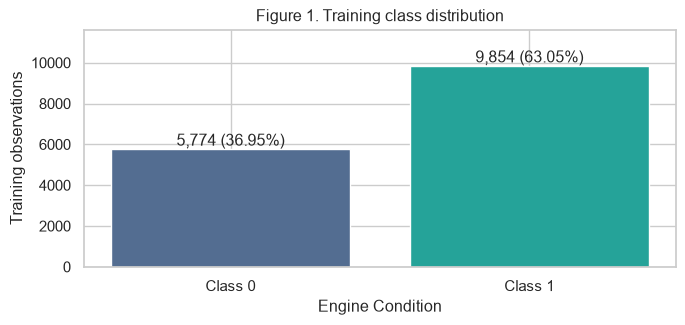

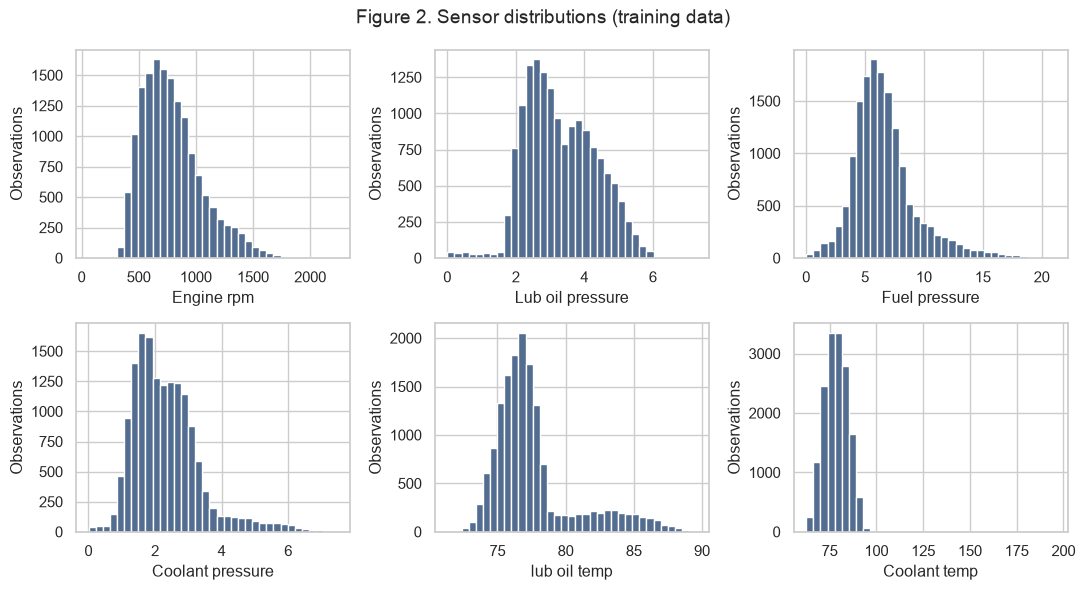

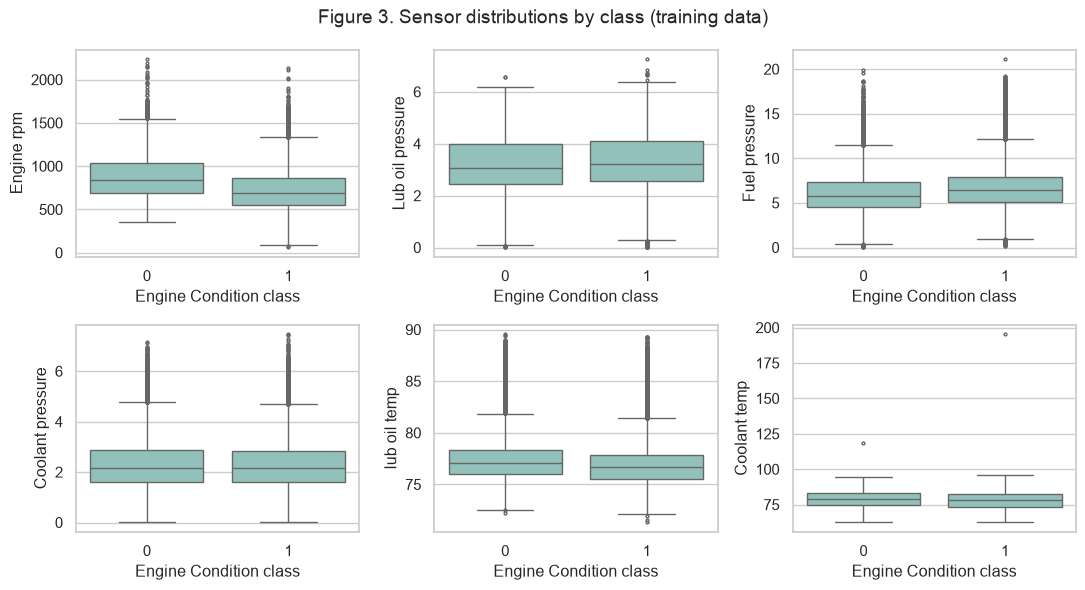

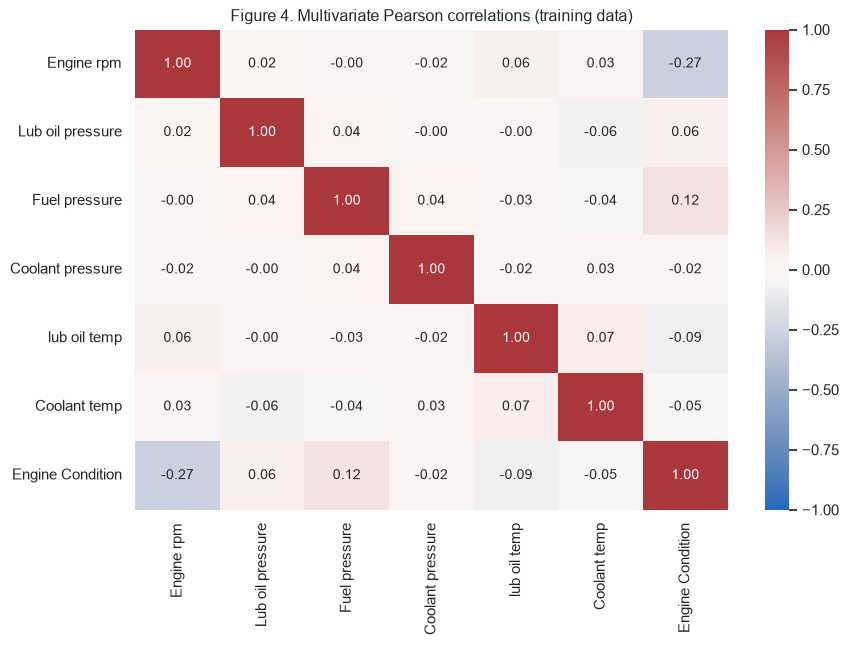

Class 1 represents 63.05% of training observations. A majority-class prediction can therefore appear accurate while never recognizing class 0; balanced accuracy and both-class diagnostics are needed.
Engine rpm averages 885.74 for class 0 and 737.49 for class 1. The distributions overlap, so rpm alone should not be used as a maintenance rule.
Engine rpm has the strongest absolute linear association with the target (r = -0.27). This describes an association with the encoded class, not a cause of engine condition.
The strongest sensor-to-sensor correlation is lub oil temp versus Coolant temp (r = 0.07). Weak pairwise correlations do not rule out nonlinear relationships or interactions.
Coolant temp has a median of 78.34 and a maximum of 195.53; 2 readings lie outside its 1.5-IQR limits. Retain these readings because they may describe unusual operating conditions; verify units and sensor calibration before applying physical limits.
No identifier, timestamp, or failure-mode field is presen

In [3]:
"""Training-only exploratory analysis and held-out diagnostic plots."""
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay


def explore(train, cfg, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    target = cfg['target']
    features = train.drop(columns=target).columns.tolist()
    sns.set_theme(style='whitegrid', font_scale=0.95)
    summary = train[features].describe().T
    q1, q3 = summary['25%'], summary['75%']
    iqr = q3 - q1
    outlier_counts = ((train[features] < q1 - 1.5*iqr) | (train[features] > q3 + 1.5*iqr)).sum()
    summary['IQR flags'] = outlier_counts
    groups = train.groupby(target)[features].mean().T
    groups.columns = ['Class 0 mean', 'Class 1 mean']
    groups['Difference (1 - 0)'] = groups['Class 1 mean'] - groups['Class 0 mean']
    corr = train.corr()
    summary.to_csv(output / 'feature_summary.csv')
    groups.to_csv(output / 'class_comparison.csv')
    corr.to_csv(output / 'correlations.csv')
    print('Table 1. Training feature overview; pressure/temperature units were not supplied.')
    display(summary.round(2))
    print('Table 2. Training feature means by class (associations, not causal effects).')
    display(groups.round(2))
    print('Table 3. Training missing values and IQR outlier flags (flags are retained).')
    display(pd.DataFrame({'Missing': train[features].isna().sum(), 'IQR flags': outlier_counts}))

    def finish(fig, number):
        fig.tight_layout()
        fig.savefig(output / f'figure_{number}.png', dpi=180, bbox_inches='tight')
        plt.show()
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3.4))
    counts = train[target].value_counts().sort_index()
    ax.bar(['Class 0', 'Class 1'], counts, color=['#536d91', '#25a399'])
    for i, count in enumerate(counts):
        ax.text(i, count, f'{count:,} ({count/len(train):.2%})', ha='center', va='bottom')
    ax.set(ylim=(0, counts.max()*1.18), xlabel='Engine Condition', ylabel='Training observations',
           title='Figure 1. Training class distribution')
    finish(fig, 1)

    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    for col, ax in zip(features, axes.flat):
        ax.hist(train[col], bins=35, color='#536d91', edgecolor='white')
        ax.set(xlabel=col, ylabel='Observations')
    fig.suptitle('Figure 2. Sensor distributions (training data)', fontsize=14)
    finish(fig, 2)

    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    for col, ax in zip(features, axes.flat):
        sns.boxplot(data=train, x=target, y=col, ax=ax, color='#8ac9c2', fliersize=2)
        ax.set(xlabel='Engine Condition class', ylabel=col)
    fig.suptitle('Figure 3. Sensor distributions by class (training data)', fontsize=14)
    finish(fig, 3)

    fig, ax = plt.subplots(figsize=(9, 6.6))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
                ax=ax, annot_kws={'size':10})
    ax.set_title('Figure 4. Multivariate Pearson correlations (training data)')
    finish(fig, 4)

    target_corr = corr[target].drop(target)
    strongest = target_corr.abs().idxmax()
    upper_triangle = np.triu(np.ones((len(features), len(features)), dtype=bool), k=1)
    feature_corr = corr.loc[features, features].where(upper_triangle).stack()
    pair = feature_corr.abs().idxmax()
    rpm_means = groups.loc['Engine rpm']
    coolant = summary.loc['Coolant temp']
    notes = [
        f'Class 1 represents {100*train[target].mean():.2f}% of training observations. A majority-class prediction can therefore appear accurate while never recognizing class 0; balanced accuracy and both-class diagnostics are needed.',
        f'Engine rpm averages {rpm_means.iloc[0]:.2f} for class 0 and {rpm_means.iloc[1]:.2f} for class 1. The distributions overlap, so rpm alone should not be used as a maintenance rule.',
        f'{strongest} has the strongest absolute linear association with the target (r = {target_corr[strongest]:.2f}). This describes an association with the encoded class, not a cause of engine condition.',
        f'The strongest sensor-to-sensor correlation is {pair[0]} versus {pair[1]} (r = {feature_corr[pair]:.2f}). Weak pairwise correlations do not rule out nonlinear relationships or interactions.',
        f'Coolant temp has a median of {coolant["50%"]:.2f} and a maximum of {coolant["max"]:.2f}; {int(outlier_counts["Coolant temp"])} readings lie outside its 1.5-IQR limits. Retain these readings because they may describe unusual operating conditions; verify units and sensor calibration before applying physical limits.',
        'No identifier, timestamp, or failure-mode field is present. All six sensor features are retained. These measurements support contemporaneous condition classification; the data cannot establish advance warning time or remaining useful life.'
    ]
    (output / 'eda_insights.json').write_text(json.dumps(notes, indent=2))
    for note in notes:
        print(note)
    return notes


def diagnostics(test, cfg, model_dir, output):
    output = Path(output)
    model = joblib.load(Path(model_dir) / 'best_model.joblib')
    metrics = json.loads((Path(model_dir) / 'metrics.json').read_text())
    y = test[cfg['target']]
    X = test.drop(columns=cfg['target'])
    probability = model.predict_proba(X)[:, 1]
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(metrics['random_forest']['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Class 0','Class 1'], yticklabels=['Class 0','Class 1'], ax=ax)
    ax.set(xlabel='Predicted class', ylabel='Actual class', title='Figure 5. Held-out confusion matrix')
    fig.tight_layout(); fig.savefig(output / 'figure_5.png', dpi=180); plt.show(); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y, probability, ax=axes[0], name='Random forest')
    axes[0].plot([0,1],[0,1], '--', color='grey', label='Chance'); axes[0].legend()
    PrecisionRecallDisplay.from_predictions(y, probability, ax=axes[1], name='Random forest')
    axes[1].axhline(y.mean(), linestyle='--', color='grey', label='Class 1 prevalence'); axes[1].legend()
    fig.suptitle('Figure 6. Held-out ranking performance (positive class = 1)')
    fig.tight_layout(); fig.savefig(output / 'figure_6.png', dpi=180); plt.show(); plt.close(fig)
    print('Table 5. Held-out metrics (positive class = 1).')
    display(pd.DataFrame({name:{k:v for k,v in metrics[name].items() if k!='confusion_matrix'}
                          for name in ['baseline','random_forest']}).round(2))
    print(f"Held-out balanced accuracy: {metrics['random_forest']['balanced_accuracy']:.2f}; "
          f"baseline: {metrics['baseline']['balanced_accuracy']:.2f}. "
          f"Class-1 F1: {metrics['random_forest']['f1']:.2f}; baseline: {metrics['baseline']['f1']:.2f}.")
    print('Selection optimized cross-validated average precision, not F1 at threshold 0.5. '
          'The majority baseline has class-1 recall of 1.00 but recognizes no class-0 observations. '
          'The forest trades some class-1 recall for class-0 recognition; threshold choice needs validation data and operational costs.')

notes = explore(train, cfg, Path("reports"))

## 3. Model building and experimentation tracking

Methodology: evaluate 16 random forest candidates using three shuffled stratified folds, seed 42. Rank by class-1 average precision; refit the winner on the training split. The test set is not used for tuning. A prior-probability dummy model is the baseline. The default decision threshold is 0.5.

{
  "baseline": {
    "average_precision": 0.6304069618633222,
    "roc_auc": 0.5,
    "balanced_accuracy": 0.5,
    "precision": 0.6304069618633222,
    "recall": 1.0,
    "f1": 0.7733124018838304,
    "confusion_matrix": [
      [
        0,
        1444
      ],
      [
        0,
        2463
      ]
    ]
  },
  "random_forest": {
    "average_precision": 0.7975690662213403,
    "roc_auc": 0.6937947551743646,
    "balanced_accuracy": 0.6469833873741344,
    "precision": 0.7616478666012751,
    "recall": 0.6305318717011774,
    "f1": 0.6899155930697468,
    "confusion_matrix": [
      [
        958,
        486
      ],
      [
        910,
        1553
      ]
    ]
  },
  "best_cv_average_precision": 0.7938184156247289,
  "best_parameters": {
    "model__class_weight": "balanced",
    "model__max_depth": 10,
    "model__min_samples_leaf": 1,
    "model__n_estimators": 100
  },
  "test_prevalence": 0.6304069618633222,
  "decision_threshold": 0.5
}
Table 4. Full experiment log, inc

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,0.975126,0.008684,0.050527,0.000537,NaN,NaN,1,100,"{'model__class_weight': None, 'model__max_dept...",0.773565,0.763755,0.775669,0.770996,0.005192,16,1.000000,1.000000,1.000000,1.000000,9.064933e-17
1,1.991102,0.012167,0.110571,0.020746,NaN,NaN,1,200,"{'model__class_weight': None, 'model__max_dept...",0.777524,0.767024,0.778131,0.774226,0.005099,14,1.000000,1.000000,1.000000,1.000000,0.000000e+00
2,0.933520,0.048115,0.045987,0.001218,NaN,NaN,3,100,"{'model__class_weight': None, 'model__max_dept...",0.783303,0.775010,0.784577,0.780963,0.004242,12,0.998629,0.998756,0.998876,0.998753,1.006587e-04
3,1.808505,0.010371,0.092934,0.003702,NaN,NaN,3,200,"{'model__class_weight': None, 'model__max_dept...",0.786407,0.774732,0.788035,0.783058,0.005925,9,0.998982,0.998972,0.999127,0.999027,7.095731e-05
4,0.718046,0.030730,0.031234,0.001263,NaN,10.0,1,100,"{'model__class_weight': None, 'model__max_dept...",0.794751,0.785108,0.797783,0.792547,0.005404,5,0.927782,0.930175,0.927004,0.928320,1.349463e-03
5,1.471039,0.011099,0.056857,0.001463,NaN,10.0,1,200,"{'model__class_weight': None, 'model__max_dept...",0.793977,0.785224,0.798351,0.792517,0.005458,6,0.928166,0.931071,0.928599,0.929278,1.279985e-03
6,0.706695,0.012646,0.028697,0.000229,NaN,10.0,3,100,"{'model__class_weight': None, 'model__max_dept...",0.792666,0.784981,0.797028,0.791558,0.004980,8,0.915419,0.920779,0.915238,0.917146,2.570594e-03
7,1.386521,0.007447,0.062167,0.003746,NaN,10.0,3,200,"{'model__class_weight': None, 'model__max_dept...",0.794592,0.785793,0.798164,0.792850,0.005198,4,0.916384,0.920318,0.916319,0.917674,1.869828e-03
8,1.058795,0.017453,0.051390,0.001040,balanced,NaN,1,100,"{'model__class_weight': 'balanced', 'model__ma...",0.777870,0.768498,0.776075,0.774147,0.004061,15,1.000000,1.000000,1.000000,1.000000,6.409876e-17
9,2.083803,0.020929,0.096518,0.001088,balanced,NaN,1,200,"{'model__class_weight': 'balanced', 'model__ma...",0.780867,0.770866,0.780167,0.777300,0.004559,13,1.000000,1.000000,1.000000,1.000000,9.064933e-17


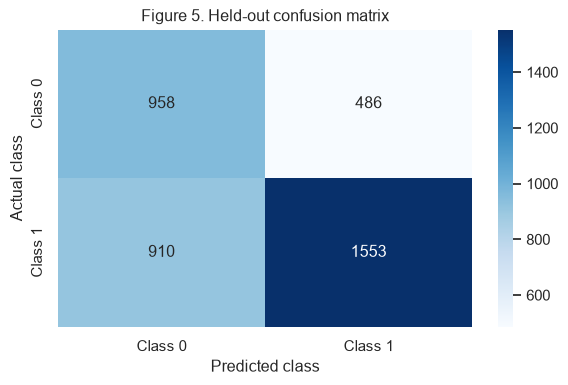

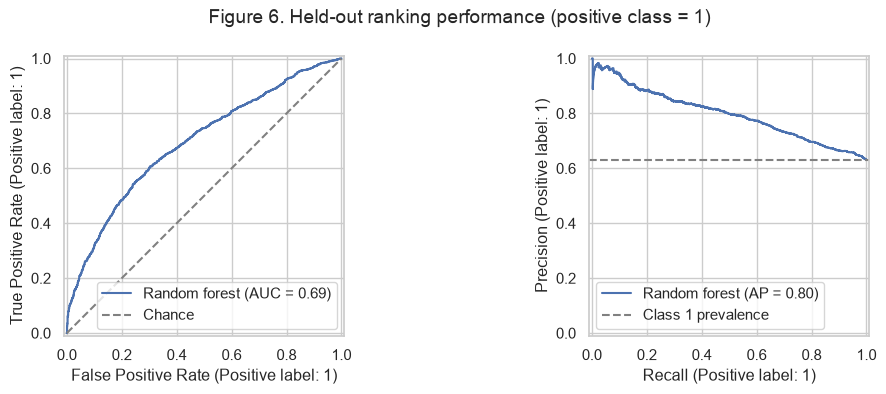

Table 5. Held-out metrics (positive class = 1).


,baseline,random_forest
average_precision,0.63,0.80
roc_auc,0.50,0.69
balanced_accuracy,0.50,0.65
precision,0.63,0.76
recall,1.00,0.63
f1,0.77,0.69


Held-out balanced accuracy: 0.65; baseline: 0.50. Class-1 F1: 0.69; baseline: 0.77.
Selection optimized cross-validated average precision, not F1 at threshold 0.5. The majority baseline has class-1 recall of 1.00 but recognizes no class-0 observations. The forest trades some class-1 recall for class-0 recognition; threshold choice needs validation data and operational costs.
Environment and dataset lineage:
{
  "configuration": {
    "dataset": "data/engine_data.csv",
    "source": "Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.",
    "learner_name": "Harshit Rathi",
    "target": "Engine Condition",
    "positive_label": 1,
    "expected_columns": [
      "Engine rpm",
      "Lub oil pressure",
      "Fuel pressure",
      "Coolant pressure",
      "lub oil temp",
      "Coola

In [4]:
metrics = train_model(cfg, splits, Path('artifacts/model'))
print('Table 4. Full experiment log, including all fold scores and tuned parameters.')
experiments = pd.read_csv('artifacts/model/experiments.csv')
with pd.option_context('display.max_columns', None, 'display.max_rows', None):
    display(experiments)
diagnostics(test, cfg, Path('artifacts/model'), Path('reports'))
print('Environment and dataset lineage:')
print(Path('artifacts/model/run_metadata.json').read_text())


## 4. Business interpretation and limitations

This is condition classification, not demonstrated prediction of future breakdown. Confirm which label denotes the maintenance-relevant condition before interpreting errors as missed faults or false alarms. Use validation data and agreed intervention costs to choose a threshold; do not optimize on the test set. Validate on new equipment and later time periods before deployment. No financial savings are claimed.